# T12 · entrenamiento online en Colab

Elige una variante y una semilla: baseline de cinco capas, conjunta 2/3/5 o controles de dos y tres capas. Usan 512 unidades por GRU, kernel 14, stride 4 y suavizado causal con retardo de 160 ms.

Entrena con CTC sobre frases completas y después evalúa por bloques. Conserva la partición T12 y la normalización fija de train por sesión.

`REANUDAR_DESDE` vacío inicia un run; con la ruta de `entrenamiento.pt`, continúa el guardado. Pesos, configuración, fuentes, entorno y registros quedan en Drive; las métricas, en W&B.


In [1]:
#@title 1. Comprobar que estamos en Colab con GPU
from pathlib import Path
import os
import subprocess
import sys

try:
    import google.colab
except ImportError as error:
    raise RuntimeError("Abre este notebook en Google Colab; no se ejecuta en el PC local.") from error

COLAB_BASE = globals().get("COLAB_BASE", Path.cwd().resolve())
PROJECT = COLAB_BASE / "tic_proyecto_online_colab"
try:
    subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total,driver_version", "--format=csv"], check=True)
except (FileNotFoundError, subprocess.CalledProcessError) as error:
    raise RuntimeError("Selecciona una GPU en Entorno de ejecución → Cambiar tipo de entorno de ejecución y vuelve a empezar.") from error
print("La instalación, preparación y entrenamiento se ejecutarán en la máquina de Colab.")


La instalación, preparación y entrenamiento se ejecutarán en la máquina de Colab.


## Cargar el código

El notebook incluye las fuentes, los perfiles de `configs/entrenos_online/` y las dependencias. Extrae el paquete y comprueba sus hashes.


In [2]:
#@title 2. Copiar el código del proyecto (snapshot incluido)
import base64
import hashlib
import io
import json
from pathlib import PurePosixPath
from zipfile import ZipFile

SOURCE_SHA256 = 'c8c96ef5bb90e8ad04a13fa1c0546ea7d765d9b0ab891631f3cce0d287b7d8ba'
SOURCE_B64 = (
    '...'
)

SOURCE_BYTES = base64.b64decode(SOURCE_B64)
if hashlib.sha256(SOURCE_BYTES).hexdigest() != SOURCE_SHA256:
    raise ValueError("El paquete de código no supera su SHA-256.")
PROJECT.mkdir(parents=True, exist_ok=True)
with ZipFile(io.BytesIO(SOURCE_BYTES)) as archive:
    for member in archive.infolist():
        relative = PurePosixPath(member.filename)
        if relative.is_absolute() or ".." in relative.parts or member.is_dir():
            raise ValueError(f"Ruta inesperada en el paquete: {member.filename}")
        destination = PROJECT.joinpath(*relative.parts)
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))
SOURCE_MANIFEST = json.loads((PROJECT / "source_snapshot.json").read_text())
for name, expected in SOURCE_MANIFEST["files"].items():
    if hashlib.sha256((PROJECT / name).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Código distinto del snapshot: {name}")
print("Código preparado:", len(SOURCE_MANIFEST["files"]), "archivos")
print("Commit base:", SOURCE_MANIFEST["git_commit_base"])
print("SHA-256 del paquete:", SOURCE_SHA256)


Código preparado: 55 archivos
Commit base: a0ec06019dc138c3b8d4b42401921d06657f9a60
SHA-256 del paquete: c8c96ef5bb90e8ad04a13fa1c0546ea7d765d9b0ab891631f3cce0d287b7d8ba


## Preparar el entorno

Crea un entorno separado del kernel con Python 3.12.11, uv 0.9.4 y PyTorch 2.5.1 con CUDA 12.4. Registra las versiones y el entorno numérico para comprobarlos al reanudar.


In [3]:
#@title 3. Instalar el entorno del proyecto
import shutil

subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", "uv==0.9.4"], check=True)
UV = shutil.which("uv")
if UV is None:
    raise RuntimeError("No se encontró uv después de instalarlo.")
PYTHON = PROJECT / ".venv" / "bin" / "python"
if not PYTHON.is_file():
    subprocess.run([UV, "venv", "--python", "3.12.11", "--seed", str(PROJECT / ".venv")], check=True)
subprocess.run([UV, "pip", "install", "--python", str(PYTHON), "-r", "requirements.txt"], cwd=PROJECT, check=True)
subprocess.run([UV, "pip", "check", "--python", str(PYTHON)], cwd=PROJECT, check=True)

def ejecutar(argumentos: list[str]) -> None:
    """Muestra stdout/stderr en Colab y conserva el motivo real si falla."""
    from collections import deque
    import signal

    recent = deque(maxlen=25)
    process = subprocess.Popen([str(PYTHON), *argumentos], cwd=PROJECT,
                               stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                               text=True, encoding="utf-8", errors="replace", bufsize=1)
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            recent.append(line)
        returncode = process.wait()
    finally:
        if process.poll() is None:
            process.send_signal(signal.SIGINT)
            try:
                process.wait(timeout=30)
            except subprocess.TimeoutExpired:
                process.terminate()
                try:
                    process.wait(timeout=10)
                except subprocess.TimeoutExpired:
                    process.kill()
                    process.wait()
        process.stdout.close()
    if returncode:
        detail = "".join(recent).strip() or "El proceso terminó sin producir salida."
        raise RuntimeError(f"Falló {argumentos[0]} (código {returncode}).\n{detail}")

print("Entorno aislado preparado. No hace falta reiniciar el kernel.")


Entorno aislado preparado. No hace falta reiniciar el kernel.


## Elegir variante, semilla y estado guardado

`INDICE_SEMILLA` selecciona una posición del plan `configs/entrenos_online/speech_online_comparativa.yaml`. Cada ejecución usa una variante y una semilla.

Deja `REANUDAR_DESDE` vacío para empezar. Para continuar, indica la ruta de `entrenamiento.pt` relativa a los checkpoints de Drive. Se guarda desde el primer paso, cada 250 pasos y al finalizar; tras un corte se repite lo posterior al último guardado.


In [4]:
#@title 4. Conectar Drive y preparar la configuración
CARPETA_DRIVE = "speech_bci" #@param {type:"string"}
VARIANTE = "baseline_5" #@param ["baseline_5", "conjunta_235", "control_2", "control_3"]
INDICE_SEMILLA = 0 #@param {type:"integer"}
REANUDAR_DESDE = "" #@param {type:"string"}
# Índice de la lista de semillas de configs/entrenos_online/speech_online_comparativa.yaml.

from datetime import datetime
from zoneinfo import ZoneInfo
from uuid import uuid4
from google.colab import drive
import json

relative = Path(CARPETA_DRIVE)
if not CARPETA_DRIVE.strip() or relative.is_absolute() or ".." in relative.parts:
    raise ValueError("Indica una carpeta relativa a Mi unidad, por ejemplo speech_bci.")
DRIVE_MOUNT = COLAB_BASE / "drive"
drive.mount(str(DRIVE_MOUNT))
DRIVE_ROOT = DRIVE_MOUNT / "MyDrive" / relative
EXPERIMENT_ID = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S") + "_" + uuid4().hex[:8]
RESULTS = DRIVE_ROOT / "experimentos" / ("online_t12_" + EXPERIMENT_ID)
RESULTS.mkdir(parents=True, exist_ok=False)
CHECKPOINTS = DRIVE_ROOT / "checkpoints"
CHECKPOINTS.mkdir(parents=True, exist_ok=True)
link = PROJECT / "checkpoints"
if link.is_symlink():
    if link.resolve() != CHECKPOINTS.resolve():
        raise RuntimeError("El enlace de checkpoints apunta a otra carpeta. Usa el mismo CARPETA_DRIVE o una sesión nueva.")
elif link.exists():
    raise RuntimeError("Existe una carpeta local checkpoints. Revísala antes de crear el enlace a Drive.")
else:
    link.symlink_to(CHECKPOINTS, target_is_directory=True)

CONFIG = "configs/entrenos_online/speech_colab.yaml"
ejecutar(["scripts/configure_speech_resume.py",
          "--plan", "configs/entrenos_online/speech_online_comparativa.yaml", "--variant", VARIANTE,
          "--seed-index", str(INDICE_SEMILLA), "--output", CONFIG])
config_code = """
from pathlib import Path
import json
import sys
import yaml
cfg = yaml.safe_load(Path(sys.argv[1]).read_text())
cfg['experimento']['nombre'] = cfg['experimento']['nombre'].removesuffix('_pytorch') + '_colab'
cfg['ejecucion']['dispositivo'] = 'cuda'
Path('configs/entrenos_online/speech_colab.yaml').write_text(yaml.safe_dump(cfg, sort_keys=False), encoding='utf-8')
print(json.dumps(cfg))
"""
cfg = json.loads(subprocess.check_output([str(PYTHON), "-c", config_code, CONFIG], cwd=PROJECT, text=True))
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[variable] = str(cfg["ejecucion"]["hilos_cpu"])
(RESULTS / "source_snapshot.json").write_text(json.dumps(SOURCE_MANIFEST, indent=2))
(RESULTS / "fuentes.zip").write_bytes(SOURCE_BYTES)
shutil.copyfile(PROJECT / CONFIG, RESULTS / "config.yaml")
print("Resultados:", RESULTS)
print("Checkpoints:", CHECKPOINTS)
print("Modelo:", cfg["modelo"])
print("Suavizado:", cfg["preprocesamiento"]["suavizado"])
print("Lote efectivo:", cfg["datos"]["batch_size"], "| microlote:", cfg["entrenamiento"]["micro_batch_size"])
print("Variante:", cfg["comparacion"]["variante"], "| semilla:", cfg["experimento"]["seed"])
print("Perfil:", cfg["comparacion"]["config_base"])
print("Actualizaciones máximas:", cfg["entrenamiento"]["pasos"], "| límite suave (s):", cfg["entrenamiento"].get("max_segundos"))
print("Microlote train:", cfg["entrenamiento"]["micro_batch_size"], "| evaluación:", cfg["evaluacion"]["micro_batch_size"])
print("W&B:", cfg["wandb"]["proyecto"], "|", cfg["wandb"]["modo"])

shutil.copyfile(PROJECT / cfg["protocolo"]["manifiesto"], RESULTS / "particion_t12_v1.json")
print("Protocolo fijo:", cfg["protocolo"]["sha256"])

RESUME_ARGUMENT = None
RESUME_FILE = None
if REANUDAR_DESDE.strip():
    relative_state = Path(REANUDAR_DESDE.strip())
    if relative_state.is_absolute() or ".." in relative_state.parts or relative_state.name != "entrenamiento.pt":
        raise ValueError("Indica una ruta relativa a checkpoints que termine en entrenamiento.pt.")
    RESUME_FILE = CHECKPOINTS / relative_state
    if not RESUME_FILE.is_file():
        raise FileNotFoundError(f"No se encuentra el estado en Drive: {RESUME_FILE}")
    RESUME_ARGUMENT = (Path("checkpoints") / relative_state).as_posix()
    info = RESUME_FILE.with_suffix(".json")
    if info.is_file():
        print("Estado orientativo guardado:", info.read_text())
    print("Se reanudará:", REANUDAR_DESDE)
else:
    print("Se iniciará un run nuevo desde cero.")
print("Persistencia:", cfg["reanudacion"])

LAST_CHECKPOINT = None
LAST_STATUS = {}
selected = None


Mounted at /content/drive
Perfil reanudable: baseline_5; semilla 0; presupuesto 10001 pasos. Configuración: configs/entrenos_online/speech_colab.yaml
Resultados: /content/drive/MyDrive/speech_bci/experimentos/online_t12_20261101_155329_fa243c5c
Checkpoints: /content/drive/MyDrive/speech_bci/checkpoints
Modelo: {'nombre': 'speech_gru', 'entrada': 256, 'capa_dia': 256, 'capas': 5, 'unidades': 512, 'bidireccional': False, 'kernel': 14, 'stride': 4, 'dropout_entrada': 0.2, 'dropout_gru': 0.4}
Suavizado: {'modo': 'causal', 'sigma': 2.0, 'retardo_bins': 8, 'umbral': 0.0, 'longitud_impulso': 100, 'truncate': 4.0}
Lote efectivo: 64 | microlote: 16
Variante: baseline_5 | semilla: 0
Perfil: configs/entrenos_online/speech_online.yaml
Actualizaciones máximas: 10001 | límite suave (s): None
Microlote train: 16 | evaluación: 16
W&B: tiiac-2026 | online
Protocolo fijo: d9043f30f4755dfef1bdfa33f454ea7025c638ae01cb8a49e182ac1aaf62ccdb
Se iniciará un run nuevo desde cero.
Persistencia: {'cada_pasos': 25

In [5]:
#@title 5. Comprobar CUDA y registrar el entorno
probe = """
import json
import platform
import sys
import torch
import numpy
import wandb
if not torch.cuda.is_available():
    raise RuntimeError('El Python del proyecto no detecta CUDA. Comprueba que Colab tiene GPU.')
major, minor = torch.cuda.get_device_capability()
maximum = max(int(name.removeprefix('sm_')) // 10 for name in torch.cuda.get_arch_list() if name.startswith('sm_'))
if major > maximum:
    raise RuntimeError('La GPU asignada necesita un PyTorch más reciente. Para conservar torch 2.5.1 usa una T4, L4 o A100 si están disponibles.')
print(json.dumps({'python': sys.version, 'platform': platform.platform(), 'torch': str(torch.__version__),
                  'numpy': numpy.__version__, 'wandb': wandb.__version__, 'cuda': torch.version.cuda,
                  'gpu': torch.cuda.get_device_name(), 'capability': [major, minor],
                  'gpu_total_mib': torch.cuda.get_device_properties(0).total_memory / (1 << 20)}, indent=2))
"""
environment = json.loads(subprocess.check_output([str(PYTHON), "-c", probe], cwd=PROJECT, text=True))
(RESULTS / "entorno.json").write_text(json.dumps(environment, indent=2))
freeze = subprocess.check_output([str(PYTHON), "-m", "pip", "freeze"], cwd=PROJECT, text=True)
(RESULTS / "paquetes.txt").write_text(freeze)
print(json.dumps(environment, indent=2))
print("Espacio libre en Colab:", round(shutil.disk_usage(PROJECT).free / (1 << 30), 1), "GiB")


{
  "python": "3.12.11 (main, Oct  7 2025, 15:34:39) [Clang 20.1.4 ]",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.5.1+cu124",
  "numpy": "2.1.3",
  "wandb": "0.18.7",
  "cuda": "12.4",
  "gpu": "NVIDIA A100-SXM4-40GB",
  "capability": [
    8,
    0
  ],
  "gpu_total_mib": 40441.375
}
Espacio libre en Colab: 230.0 GiB


## Cargar y preparar competitionData

Obtiene `competitionData.tar.gz` desde Drive o Dryad y comprueba su tamaño y SHA-256 antes de extraerlo. `ARCHIVO_DATOS_DRIVE` admite una ruta concreta; si está vacío, busca el archivo en Mi unidad. La opción Drive utiliza una copia existente; Dryad realiza la descarga pública.

La preparación genera fonemas con g2p-en, ajusta la normalización con train y guarda las señales en NPY por sesión.

La partición contiene 5.180 frases de entrenamiento, 1.460 de validación y 680 de test. La selección de pesos usa validación.


In [6]:
#@title 6. Obtener y extraer competitionData
ORIGEN_DATOS = "Drive" #@param ["Drive", "Dryad"]
ARCHIVO_DATOS_DRIVE = "" #@param {type:"string"}


def buscar_archivos_drive(root: Path) -> tuple[list[Path], bool]:
    """Busca el tar de competitionData por nombre, sin leer su contenido."""
    import time

    matches = []
    started = time.monotonic()
    visited = 0
    incomplete = False
    errors = []
    for current, directories, filenames in os.walk(root, onerror=errors.append, followlinks=False):
        visited += 1
        folder = Path(current)
        if len(folder.relative_to(root).parts) >= 5:
            incomplete = incomplete or bool(directories)
            directories.clear()
        else:
            directories[:] = sorted(name for name in directories if not name.startswith('.'))
        for name in sorted(filenames):
            if name.casefold().startswith('competitiondata') and name.casefold().endswith(('.tar.gz', '.tgz')):
                matches.append(folder / name)
        if visited >= 200 or time.monotonic() - started >= 15:
            incomplete = True
            break
    return matches, incomplete or bool(errors)


manifest = json.loads((PROJECT / "docs/datasets/speech_2023/manifest.json").read_text())
expected = next(item for item in manifest["files"] if item["name"] == "competitionData.tar.gz")
destination = PROJECT / "data" / "speech_2023" / expected["name"]
destination.parent.mkdir(parents=True, exist_ok=True)
my_drive = DRIVE_MOUNT / "MyDrive"
print("Tamaño esperado:", expected["size_bytes"], "bytes")
print("Espacio libre en Colab:", round(shutil.disk_usage(PROJECT).free / (1 << 30), 1), "GiB")
if ORIGEN_DATOS not in ("Drive", "Dryad"):
    raise ValueError("Selecciona Drive o Dryad en ORIGEN_DATOS.")

local_valid = False
if destination.is_file():
    try:
        ejecutar(["scripts/get_data.py", "--dataset", "speech_2023", "--files", expected["name"], "--verify-only"])
        local_valid = True
        print("Se reutiliza la copia local verificada.")
    except RuntimeError:
        print("La copia local no es válida; solo se sustituirá por un archivo verificado.")

if not local_valid and ORIGEN_DATOS == "Drive":
    if not my_drive.is_dir():
        raise RuntimeError("Drive no está disponible. Ejecuta la celda 4 para montarlo antes de continuar.")
    entered = ARCHIVO_DATOS_DRIVE.strip().strip("\"'")
    if entered:
        selected = Path(entered)
        if ".." in selected.parts:
            raise ValueError("Indica la ruta del archivo sin componentes '..'.")
        if selected.is_absolute():
            if not selected.is_relative_to(DRIVE_MOUNT):
                raise ValueError(f"La ruta debe estar dentro del Drive montado en {DRIVE_MOUNT}.")
            source = selected
        elif selected.parts and selected.parts[0] in ("MyDrive", "Shareddrives"):
            source = DRIVE_MOUNT / selected
        else:
            source = my_drive / selected
        if not source.is_file():
            raise FileNotFoundError(
                f"Colab no ve un archivo en: {source}\n"
                "En el panel Archivos, localízalo dentro de drive y usa 'Copiar ruta'. "
                "Comprueba que Drive está montado con la cuenta donde subiste el archivo. "
                "No se ha intentado descargar de Dryad."
            )
    else:
        candidates = [DRIVE_ROOT / "datos" / expected["name"], DRIVE_ROOT / expected["name"], my_drive / expected["name"]]
        source = next((candidate for candidate in candidates if candidate.is_file()), None)
        if source is None:
            print("Buscando competitionData en Mi unidad (hasta 5 niveles y 200 carpetas)...", flush=True)
            matches, incomplete = buscar_archivos_drive(my_drive)
            if incomplete:
                print("Búsqueda limitada: puede haber otras carpetas. Puedes indicar la ruta exacta.")
            complete = [candidate for candidate in matches if candidate.stat().st_size == expected["size_bytes"]]
            choices = complete or matches
            if len(choices) == 1:
                source = choices[0]
            else:
                if choices:
                    detail = "Se han encontrado varios archivos:\n" + "\n".join(str(candidate) for candidate in choices)
                else:
                    detail = "No se encontró el archivo. Rutas iniciales comprobadas:\n" + "\n".join(str(candidate) for candidate in candidates)
                raise RuntimeError(
                    f"{detail}\n\nEn el panel Archivos de Colab, localiza el archivo dentro de drive, "
                    "pulsa 'Copiar ruta' y pégala en ARCHIVO_DATOS_DRIVE. "
                    "Comprueba la cuenta de Drive si no aparece en el panel. "
                    "Vuelve a ejecutar solo esta celda. No se ha intentado descargar de Dryad."
                )
    print("Archivo encontrado en Drive:", source, flush=True)
    size = source.stat().st_size
    if size != expected["size_bytes"]:
        raise ValueError(f"El archivo de Drive tiene {size} bytes; se esperaban {expected['size_bytes']}. Comprueba que terminó la subida y que es el archivo original del 1 de septiembre de 2023.")
    temporary = destination.with_name(destination.name + ".drive.part")
    print("Copiando al disco de Colab; después se comprobará el SHA-256...", flush=True)
    shutil.copyfile(source, temporary)
    verification = """
from pathlib import Path
import sys
from scripts.get_data import leer_manifiesto, verificar
source = next(item for item in leer_manifiesto('speech_2023')['files'] if item['name'] == 'competitionData.tar.gz')
verificar(Path(sys.argv[1]), source)
print('Copia de Drive: tamaño y SHA-256 oficiales verificados.')
"""
    ejecutar(["-c", verification, str(temporary)])
    temporary.replace(destination)
elif not local_valid:
    ejecutar(["scripts/get_data.py", "--dataset", "speech_2023", "--files", expected["name"]])

extract = """
from pathlib import Path
import json
import tarfile
import yaml
cfg = yaml.safe_load(Path('configs/entrenos_online/speech_colab.yaml').read_text())
manifest = json.loads(Path('docs/datasets/speech_2023/manifest.json').read_text())
digest = next(item['sha256'] for item in manifest['files'] if item['name'] == 'competitionData.tar.gz')
marker = Path('data/speech_2023/.extraccion_verificada')
expected = [Path(cfg['datos']['raiz']) / split / (session + '.mat') for split in ['train', 'test'] for session in cfg['datos']['sesiones']]
if not marker.exists() or marker.read_text().strip() != digest or not all(path.is_file() for path in expected):
    with tarfile.open('data/speech_2023/competitionData.tar.gz') as archive:
        archive.extractall('data/speech_2023', filter='data')
    marker.write_text(digest)
print('Extraídas las señales originales. Las 19 sesiones seleccionadas están disponibles.')
"""
ejecutar(["-c", extract])


Tamaño esperado: 3669638707 bytes
Espacio libre en Colab: 230.0 GiB
Archivo encontrado en Drive: /content/drive/MyDrive/speech_bci/datos/competitionData.tar.gz
Copiando al disco de Colab; después se comprobará el SHA-256...
Copia de Drive: tamaño y SHA-256 oficiales verificados.
Extraídas las señales originales. Las 19 sesiones seleccionadas están disponibles.


In [7]:
#@title 7. Preparar recursos, fonemas y señales
REHACER_PREPARACION = False #@param {type:"boolean"}

ejecutar(["scripts/get_phoneme_resources.py", "--config", CONFIG])
labels = PROJECT / cfg["etiquetas"]["salida"] / "manifest.json"
signals = PROJECT / cfg["datos"]["preparados"] / "manifest.json"
if REHACER_PREPARACION or not labels.is_file():
    ejecutar(["scripts/prepare_phoneme_labels.py", "--config", CONFIG])
if REHACER_PREPARACION or not signals.is_file():
    ejecutar(["scripts/prepare_speech_data.py", "--config", CONFIG])
verify = """
from pathlib import Path
import json
import yaml
from src.data.speech_dataset import SpeechDataset
from src.data.speech_protocol import read_speech_protocol
cfg = yaml.safe_load(Path('configs/entrenos_online/speech_colab.yaml').read_text())
protocol = read_speech_protocol(cfg)
train = SpeechDataset(cfg, 'train')
val = SpeechDataset(cfg, 'val')
if (len(train), len(val), len(train.sessions)) != (5180, 1460, 19):
    raise ValueError('Los datos no corresponden al protocolo T12 fijado.')
if protocol['totals']['test'] != 680:
    raise ValueError('El test oficial ha cambiado.')
print(json.dumps({'train': len(train), 'val': len(val), 'test_reservado': 680,
                  'sesiones': len(train.sessions), 'normalizacion': 'solo train',
                  'hashes': 'verificados', 'protocolo_sha256': cfg['protocolo']['sha256']}, indent=2))
"""
ejecutar(["-c", verify])
shutil.copyfile(signals, RESULTS / "manifiesto_preparacion.json")
shutil.copyfile(labels, RESULTS / "manifiesto_fonemas.json")


Verificado y extraído: corpora/cmudict.zip
Verificado y extraído: taggers/averaged_perceptron_tagger.zip
Verificado y extraído: taggers/averaged_perceptron_tagger_eng.zip
Recursos de fonemas preparados y verificados.
/content/tic_proyecto_online_colab/.venv/lib/python3.12/site-packages/g2p_en/g2p.py:156: SyntaxWarning: invalid escape sequence '\-'
  text = re.sub("[^ a-z'.,?!\-]", "", text)
Etiquetas preparadas: t12.2022.04.28
Etiquetas preparadas: t12.2022.05.05
Etiquetas preparadas: t12.2022.05.17
Etiquetas preparadas: t12.2022.05.19
Etiquetas preparadas: t12.2022.05.24
Etiquetas preparadas: t12.2022.05.26
Etiquetas preparadas: t12.2022.06.02
Etiquetas preparadas: t12.2022.06.07
Etiquetas preparadas: t12.2022.06.14
Etiquetas preparadas: t12.2022.06.16
Etiquetas preparadas: t12.2022.06.21
Etiquetas preparadas: t12.2022.06.28
Etiquetas preparadas: t12.2022.07.05
Etiquetas preparadas: t12.2022.07.14
Etiquetas preparadas: t12.2022.07.21
Etiquetas preparadas: t12.2022.07.27
Etiquetas prep

PosixPath('/content/drive/MyDrive/speech_bci/experimentos/online_t12_20261101_155329_fa243c5c/manifiesto_fonemas.json')

## Conectar W&B

Busca `WANDB_API_KEY` en el entorno, en el `.env` del proyecto o de la carpeta elegida en Drive y en Secretos de Colab. Si no aparece, la solicita mediante una entrada oculta.

Registra las métricas online en `tiiac-2026` y recupera el mismo ID de W&B al continuar un entrenamiento.


In [8]:
#@title 8. Cargar la credencial de W&B sin mostrarla
import getpass

if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from src.utils.env import cargar_clave_wandb

if not cargar_clave_wandb(PROJECT / ".env", DRIVE_ROOT / ".env"):
    from google.colab import userdata
    try:
        api_key = userdata.get("WANDB_API_KEY")
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError, userdata.TimeoutException):
        api_key = None
    if not api_key or not api_key.strip():
        api_key = getpass.getpass("API key de W&B (entrada oculta): ")
    if not api_key or not api_key.strip():
        raise ValueError("Falta la credencial de W&B.")
    os.environ["WANDB_API_KEY"] = api_key.strip()
    del api_key
print("Credencial cargada. W&B mostrará el enlace del run al iniciar el entrenamiento.")


Credencial cargada. W&B mostrará el enlace del run al iniciar el entrenamiento.


## Entrenar o reanudar

Ejecuta `run.py` con el perfil elegido. Recupera pesos, Adam, muestreo, estados aleatorios e historial si has indicado un estado guardado.

`mejor_val.pt` se selecciona por mínimo PER de la salida final sobre toda validación, conservando el primero en empate. `entrenamiento.pt` permite continuar; `mejor_val.pt` y `ultimo.pt` son los checkpoints causales de inferencia.


In [9]:
#@title 9. Entrenar o reanudar y guardar en Drive
import signal
import time

if not os.environ.get("WANDB_API_KEY"):
    raise RuntimeError("Ejecuta primero la celda de autenticación de W&B.")
shutil.copyfile(PROJECT / CONFIG, RESULTS / "config.yaml")
checkpoint_root = CHECKPOINTS / Path(cfg["salida"]["directorio"]).relative_to("checkpoints")
before = set(checkpoint_root.glob("*/entrenamiento.pt"))
started = time.perf_counter()
process = None
status = {"completo": False, "estado": "iniciado", "config": CONFIG}
LAST_CHECKPOINT = None
try:
    with (RESULTS / "entrenamiento.log").open("w", encoding="utf-8") as log:
        command = [str(PYTHON), "-u", "run.py", "--config", CONFIG]
        if RESUME_ARGUMENT is not None:
            command += ["--reanudar", RESUME_ARGUMENT]
        process = subprocess.Popen(command, cwd=PROJECT,
                                   stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                   text=True, encoding="utf-8", errors="replace", bufsize=1)
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
            log.flush()
        returncode = process.wait()
    status.update(estado="terminado" if returncode == 0 else "fallido", returncode=returncode, completo=returncode == 0)
    if returncode:
        raise RuntimeError(f"El entrenamiento terminó con código {returncode}; revisa la salida y el log en Drive.")
except KeyboardInterrupt:
    status["estado"] = "interrumpido"
    raise
except BaseException:
    status["estado"] = "fallido"
    raise
finally:
    if process is not None and process.poll() is None:
        process.send_signal(signal.SIGINT)
        try:
            process.wait(timeout=30)
        except subprocess.TimeoutExpired:
            process.terminate()
            try:
                process.wait(timeout=10)
            except subprocess.TimeoutExpired:
                process.kill()
                process.wait()
    created = set(checkpoint_root.glob("*/entrenamiento.pt")) - before
    state_file = RESUME_FILE
    if state_file is None and len(created) == 1:
        state_file = next(iter(created))
    if state_file is not None and state_file.is_file():
        status["entrenamiento"] = str(state_file.relative_to(CHECKPOINTS))
        best = state_file.parent / "mejor_val.pt"
        if best.is_file():
            LAST_CHECKPOINT = best
            status["checkpoint"] = str(best)
        print("Para continuar, REANUDAR_DESDE =", repr(status["entrenamiento"]))
    elif len(created) > 1:
        status["estados_detectados"] = sorted(str(path.relative_to(CHECKPOINTS)) for path in created)
        print("Hay varios estados nuevos; identifica el run por su enlace W&B.")
    status["segundos_pared"] = time.perf_counter() - started
    if process is not None:
        status["returncode"] = process.returncode
    (RESULTS / "estado.json").write_text(json.dumps(status, indent=2), encoding="utf-8")
    LAST_STATUS = status
    print("\nRegistros en Drive:", RESULTS)
    print("Checkpoint:", LAST_CHECKPOINT or "Todavía no se había guardado ningún checkpoint de este run.")


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261101_145804-jaovk23p
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_online_baseline_seed0_colab
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/jaovk23p
dispositivo: cuda (NVIDIA A100-SXM4-40GB)  hilos CPU=2  train=5180  val=1460
lote efectivo: 64  microlote train: 16  microlote val: 16
paso 1/10001  ctc=194.6225  l2=0.0548  lr=0.020000  pico CUDA asignado=461 MiB  reservado=666 MiB
val: PER=89.66%  CTC=211.7787  frases=1460  completo=True
paso 10/10001  ctc=140.0947  l2=0.0548  lr=0.019982  pico CUDA asignado=717 MiB  reservado=1014 MiB
paso 20/10001  ctc=1

## Guardar el resumen y las curvas

Genera el resumen de la sesión finalizada o pausada desde los registros guardados. Tras un corte abrupto, la reanudación restaura primero los checkpoints de inferencia y el informe desde `entrenamiento.pt`.


Checkpoint seleccionado por validación: /content/drive/MyDrive/speech_bci/checkpoints/speech_online_baseline/jaovk23p/mejor_val.pt
{
  "step": 9951,
  "split": "val",
  "ctc_loss": 36.354865181282776,
  "per": 0.31899641577060933,
  "errores": 13261,
  "fonemas": 41571,
  "frases": 1460,
  "completo": 1,
  "segundos": 1.9579372000007425
}
{
  "run_id": "jaovk23p",
  "completed_steps": 10001,
  "experiment_name": "speech_online_baseline_seed0_colab",
  "seed": 0,
  "model_layers": 5,
  "available_exits": [
    5
  ],
  "comparison": {
    "variante": "baseline_5",
    "plan": "configs/entrenos_online/speech_online_comparativa.yaml",
    "plan_sha256": "6beb99e1b06419854812eafef1c3f422f39217af2ac8ef87c9a6b3ec70f5a84c",
    "config_base": "configs/entrenos_online/speech_online.yaml",
    "config_base_sha256": "85802b71f9cf0c67f7909d9f0cd77ca53fb02cc82027423ae55b920d66b520a2"
  },
  "planned_steps": 10001,
  "completed_budget": true,
  "best_val_step": 9951,
  "best_val": {
    "ctc_loss":

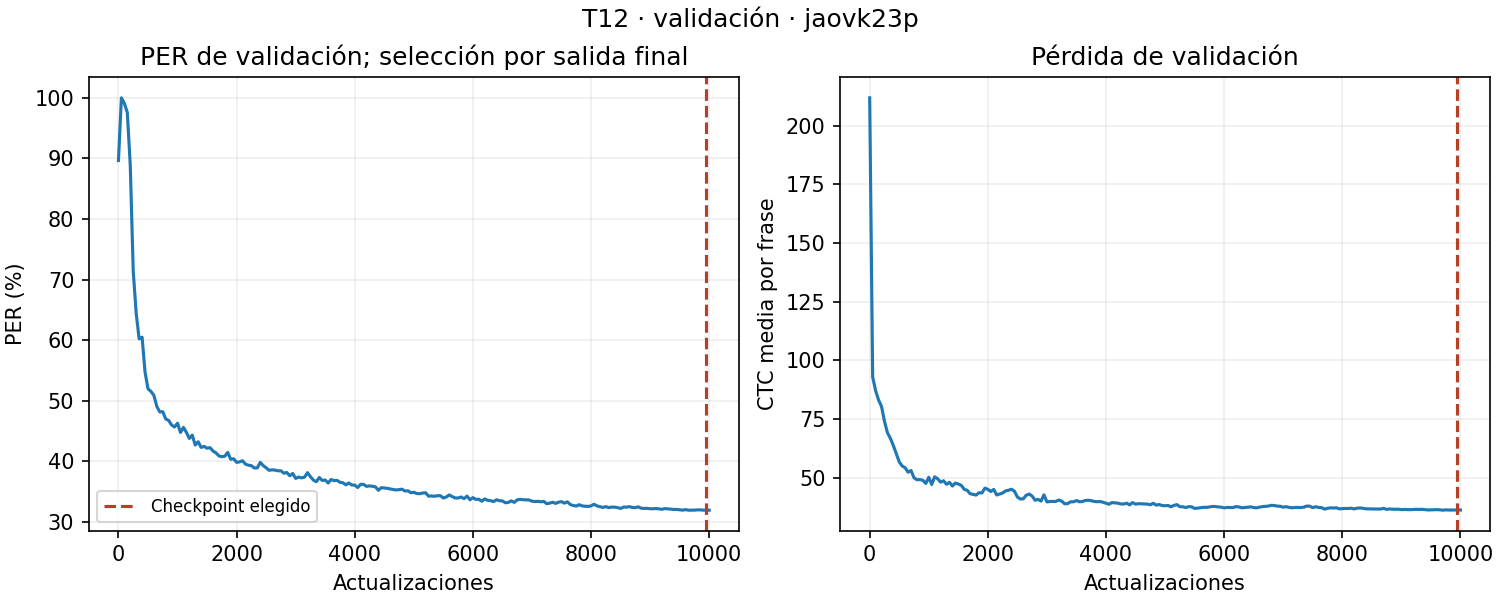

Fuentes, configuración, entorno, log y estado de esta sesión: /content/drive/MyDrive/speech_bci/experimentos/online_t12_20261101_155329_fa243c5c


In [10]:
#@title 10. Resumen y curvas guardadas (sin entrenar ni evaluar test)
CHECKPOINT_GUARDADO = "" #@param {type:"string"}

selected = globals().get("LAST_CHECKPOINT")
if CHECKPOINT_GUARDADO.strip():
    relative = Path(CHECKPOINT_GUARDADO.strip())
    if relative.is_absolute() or ".." in relative.parts:
        raise ValueError("La ruta debe ser relativa a la carpeta de checkpoints de Drive.")
    selected = CHECKPOINTS / relative
if selected is None:
    for path in sorted((CHECKPOINTS / Path(cfg["salida"]["directorio"]).relative_to("checkpoints")).glob("*/mejor_val.json")):
        print(path.relative_to(CHECKPOINTS))
    print("Indica CHECKPOINT_GUARDADO para consultar uno de los runs.")
else:
    if selected.name != "mejor_val.pt" or not selected.is_file():
        raise ValueError("Selecciona el mejor_val.pt del run de comparación.")
    print("Checkpoint seleccionado por validación:", selected)
    print(json.dumps(json.loads(selected.with_suffix(".json").read_text()), indent=2))
    result_path = selected.parent / "resultado.json"
    if not globals().get("LAST_STATUS", {}).get("completo") or not result_path.is_file():
        print("Reanuda primero el estado confirmado; no se genera un informe de cierre con archivos potencialmente desfasados.")
        latest = selected.parent / "ultimo.json"
        if latest.is_file():
            print("Último paso guardado:", latest.read_text())
    else:
        ejecutar(["scripts/report_speech_training.py", "--run-dir", str(selected.parent)])
        summary_name = "resumen_salidas.json" if cfg["modelo"].get("salidas_intermedias") else "resumen_baseline.json"
        for name in ("resultado.json", summary_name, "curvas_validacion.png"):
            shutil.copyfile(selected.parent / name, RESULTS / name)
        from IPython.display import Image, display
        display(Image(filename=str(RESULTS / "curvas_validacion.png")))
print("Fuentes, configuración, entorno, log y estado de esta sesión:", RESULTS)


## Comprobar la recarga

Carga el checkpoint en un proceso nuevo y evalúa toda la validación. Compara recuentos, PER y CTC con las métricas guardadas usando las tolerancias configuradas.

Predice la primera frase de validación con las salidas disponibles y comprueba que cada perfil ejecuta las GRU hasta su capa.


In [11]:
#@title 11. Recarga independiente, validación y predicción por perfil
if not globals().get("LAST_STATUS", {}).get("completo"):
    raise RuntimeError("Reanuda y termina normalmente la sesión antes de evaluar o medir estos pesos.")
if selected is None or not selected.is_file():
    raise RuntimeError("Selecciona primero un checkpoint en la celda 10.")
ejecutar(["scripts/verify_speech_checkpoint.py", "--config", CONFIG,
          "--checkpoint", str(selected)])
for name in ("verificacion_recarga.json", "predicciones_val_ejemplo.json"):
    shutil.copyfile(selected.parent / name, RESULTS / name)
verification = json.loads((RESULTS / "verificacion_recarga.json").read_text())
if verification["verified"] is not True or verification["optimizer_steps"] != 0:
    raise RuntimeError("La recarga no quedó verificada.")
print("Recarga correcta, cero actualizaciones y sin test. Paso:", verification["checkpoint_step"])
print("Referencia:", verification["example"]["reference_text"])
for depth, profile in verification["example"]["profiles"].items():
    print("Salida", depth, "· GRU ejecutadas", profile["executed_layers"])
    print(" ".join(profile["hypothesis_phones"]))
print("Evidencia y predicciones:", RESULTS)


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261101_153322-6zt3i1y5
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_online_baseline_seed0_colab_recarga_val
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/6zt3i1y5
wandb:                                                                                
wandb: 
wandb: Run history:
wandb: val_recarga/capa_5/completo ▁
wandb: val_recarga/capa_5/ctc_loss ▁
wandb:  val_recarga/capa_5/errores ▁
wandb:  val_recarga/capa_5/fonemas ▁
wandb:   val_recarga/capa_5/frases ▁
wandb:      val_recarga/capa_5/per ▁
wandb: 
wandb: Run summary:
wandb:              checkpoint/pas

## Evaluar por bloques

Recorre toda validación con paquetes de 80 ms y comprueba que los fonemas coinciden con una pasada completa del mismo modelo causal.

Registra PER global y por sesión, tiempo de proceso por bloque, factor de tiempo real (RTF) y llegada simulada del primer fonema. Los tiempos excluyen lectura de archivos y escritura de resultados; la llegada se simula sin HTTP ni esperas reales.

Elige CPU o CUDA para esta medición. La configuración usada, las métricas y las emisiones por bloque se guardan en Drive; el resumen también se registra en W&B.


In [14]:
#@title 12. Evaluar PER y tiempos por bloques (solo val)
DISPOSITIVO_EVALUACION = "cuda" #@param ["cpu", "cuda"]

if not globals().get("LAST_STATUS", {}).get("completo"):
    raise RuntimeError("Reanuda y termina normalmente la sesión antes de evaluar estos pesos.")
if selected is None or not selected.is_file():
    raise RuntimeError("Selecciona primero un checkpoint en la celda 10.")

EVALUATION_CONFIG = "configs/entrenos_online/evaluacion_colab.yaml"
evaluation_code = """
from pathlib import Path
import sys
import yaml
spec = yaml.safe_load(Path(sys.argv[1]).read_text())
spec['dispositivo'] = sys.argv[3]
Path(sys.argv[2]).write_text(yaml.safe_dump(spec, sort_keys=False), encoding='utf-8')
"""
ejecutar(["-c", evaluation_code, "configs/entrenos_online/speech_online_evaluacion.yaml",
          EVALUATION_CONFIG, DISPOSITIVO_EVALUACION])
evaluation_output = RESULTS / ("online_val_" + uuid4().hex[:8])
ejecutar(["scripts/evaluate_speech_online.py", "--checkpoint", str(selected),
          "--evaluation-config", EVALUATION_CONFIG, "--split", "val", "--output", str(evaluation_output)])
shutil.copyfile(PROJECT / EVALUATION_CONFIG, evaluation_output / "config.yaml")
evaluation = json.loads((evaluation_output / "metricas.json").read_text())
print("Dispositivo:", evaluation["runtime"]["device"], "·", evaluation["runtime"]["hardware"])
print("Firma de inferencia:", evaluation["inference_sha256"])
for depth, metrics in evaluation["global"].items():
    timing = evaluation["timing"][depth]
    print("Salida", depth, "· PER", f"{metrics['per']:.2%}",
          f"({metrics['errores']}/{metrics['fonemas']})", "· RTF", round(timing["rtf"], 4))
    print("  Proceso por bloque, mediana (ms):", timing["packet_processing"]["p50_ms"])
    print("  Primer fonema, reloj simulado, mediana (ms):", timing["first_phone_ready"]["p50_ms"])
print("Métricas y emisiones por bloque:", evaluation_output)


wandb: Using wandb-core as the SDK backend.  Please refer to https://wandb.me/wandb-core for more information.
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261101_155545-s6x3qt7j
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_online_baseline_seed0_colab_online_val
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/s6x3qt7j
wandb:                                                                                
wandb: 🚀 View run speech_online_baseline_seed0_colab_online_val at: https://wandb.ai/aaurre-deusto/tiiac-2026/runs/s6x3qt7j
wandb: ⭐️ View project at: https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: runs/tracking/

RuntimeError: Falló scripts/evaluate_speech_online.py (código 1).
wandb: Currently logged in as: aaurre (aaurre-deusto). Use `wandb login --relogin` to force relogin
wandb: Tracking run with wandb version 0.18.7
wandb: Run data is saved locally in runs/tracking/wandb/run-20261101_155545-s6x3qt7j
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run speech_online_baseline_seed0_colab_online_val
wandb: ⭐️ View project at https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: 🚀 View run at https://wandb.ai/aaurre-deusto/tiiac-2026/runs/s6x3qt7j
wandb:                                                                                
wandb: 🚀 View run speech_online_baseline_seed0_colab_online_val at: https://wandb.ai/aaurre-deusto/tiiac-2026/runs/s6x3qt7j
wandb: ⭐️ View project at: https://wandb.ai/aaurre-deusto/tiiac-2026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: runs/tracking/wandb/run-20261101_155545-s6x3qt7j/logs
Trace

## Continuar la evaluación en FP32




In [ ]:
#@title 14. Continuar la evaluación en FP32 (sin entrenar)
# Copia solo esta celda al final de la sesión de Colab que sigue abierta.
import base64
import hashlib
import io
import json
import shutil
from zipfile import ZipFile
from uuid import uuid4

if not globals().get("LAST_STATUS", {}).get("completo"):
    raise RuntimeError("Esta recuperación requiere la sesión abierta con el entrenamiento terminado.")
if selected is None or not selected.is_file():
    raise RuntimeError("Falta el checkpoint seleccionado en la celda 10.")

PATCH_SHA256 = 'e49b7881c80458e230f2453677fa822582d85d4d232fcfca8f42e99ef1e131d5'
PATCH_B64 = (
    'UEsDBBQAAAAIAAAAIQBoCkgv/AEAADADAAA1AAAAY29uZmlncy9lbnRyZW5vc19vbmxpbmUvc3BlZWNoX29ubGluZV9ldmFsdWFjaW9uLnlhbWxlk89uE0EM'
    'xu/7FJZ6Tbb50wpIxaEKRJxQhBaukTPrTax6ZpbxbCi8DUcOHBCPkBfDkyZqJS4ry2P//Pmb2Sv4gsItOj7+DeCi74Uy1tCQZtAoEVDAUUqYQBCUhNxTbUvg'
    'Y0sSta60F84LOKBUesLpAsIgUm0lfh1os+VgmRuAK1ijJTJp6X89Aa93UE6hmc5KalZSdeVQKGT0bN+4gGnpXCVUAg7s2DT1MUFPqWMZAT06GWxqAQgqeGqt'
    'KAYyUsvaR+XMB+O4fqj2bJI3Fi1gVpmeRI71shGHjhIFm2DQXo6/HWccgSnZ8vFXKGYUeILM5I0LFGD5+d19XZkWb1PSJnfz2QI6FCXDL81RLOY9UAokCqv1'
    'fHbxOep1WePJJH0xxgx3p20siLVh7qeTCSgHaFaF7o8/H9lHiFuldMA2wnT0Zkrj2ztDX4rmo/krGs/gOyybJZgPmc3MQnuvGSFHoYSnVbE16QRkrib2lMCh'
    'RutT3g0EZtAef2CwKVahtBssLJiPsbwA7ti0FtufiafbtT5Mu7KGmcZqcruYvmFqr92e3EMfTU5dSdxx1g1as91zPaHxzSWXnnO3Nq45W27oPkVH+mJ/e0Ui'
    'tEN7eabaD3KOAnxomjUEBhWivqj+1KzgLejgTwbn/6HX0A7p/EPkmO3K7VDp+Aelrv4BUEsDBBQAAAAIAAAAIQDFazGIJgsAAJ8hAAAhAAAAc2NyaXB0cy9l'
    'dmFsdWF0ZV9zcGVlY2hfb25saW5lLnB5zVpbb+S2FX6fX8GqaK1BZuXN9oLCgQqkGwcoUGQXcdKicA2BljgzzEqiQlK2J4Z/TB/7kKe89dV/rN/hZSTNxfam'
    'QNF5WOtyeHh4Lt/5SG2SJOc3vH78N2fvz79mG2alaDplWKc0u67V970wrBKsb1m5FuWHTsnWspL3htcLZmTLRGu1aLnOZrMvhIFozZnmjz/+gGE10wLKpFVa'
    'qgUrVbujiESCgkbiQjHV1rIVZzOGX7exawwxpZadNacChvbcisJ0QpTrwotm3Ya9ejXS+f784t1F1lk8Vb3test035pTL11Ax2z2reEMF26RlViK0qrPIG66'
    'WlpmhcEQYYS+4bQYP20pH39q2VK2GCbuuvrxx1Jans2SJJnNllo1rCiWve21KAom4UJtGW9bZbmVqjWzWXymVx3XRsT7UnWbeP2dUa3X1XG7ruV1VPQet1Go'
    'q7ldKt3Ee7MxfoyVjYgDOqGXRan61gq9nRpRKLdqNryBIzA4o7ky2WK9Nn2NmFqd0nwp1iNrrGaewRmqvhHpHLIIlTWXn17N52HZRpdZxeGKEBW6NsJGSy7c'
    '0y/8wwVzKs2av/nd74fhsl0K6C1F0BHHvnMhCxpEqSosZjvIai5b2a6ySTYUIUng86ilknzVKiOihNWScnebTf7xgkn4aiJjhsl6K2uTGSGqqHUpv+O6oCe7'
    'UjCs/ADDtllwraUukIMLZNVKwr8cMZkh71iDJaRz9uqPDInrcx75RNmJvEO1LOWq1yH1qFRGWb5hq57rirPm8V+wtuQGj0QjDVYuxuWbUYa6aqK00yzfpmD2'
    'uV71DeL53r1JK+ErDRryoqhUidiPRma8qgoehqTJuOaSBbObTuSUN7TK73upRZV/o3vxpIYhWK/8aqeK4CLe19bdpYmXAAw4vFAmxOr0UPxLqMwoxZP5kwa4'
    'isek5VrJUpg8TTAc9wmBwDNjPbj83KXHrMR4gOfK5G8WrBGW33ANKy7OL/787isy5Pyri8///i6ZL5yyQ7+1qLs8easazITEUStpHWQDwYCthm+Uyx231M9Y'
    'q4DeddnX48xpJWWpYH/79Z+yxJtNNiFXgvXuD9lvUv8aTi/xmlycGb4URa14lZJANgS18CEDfvCqsOLOpihyVaE28qS3y1d/iB6WSzdf5gFYwiBl2Vcq9oE4'
    '4WXi43XlkzjIRw0UhtSLAf4aaVF1dvmbN8nVPKq8VqoeVAJA4KK/wlpxrrXS6XQcvHYtGJUMehaNFBzO22K/ip76JfuSsIDx5hp9kwNynftLWMj1aXC2BuCg'
    'V9bsve9pKEwmvhNlb3d7TOaUOqzOroEkoq1MVvYVzxpum77OeF2rW29hzg6u94iGtv24sQDsou2bwq4pgCb4di1r1F7Z9fCrE67EDWoH+vwofxuEK2lc/5c3'
    'KoojUl4ko4C5sIBFoLyhEflOK03mTwXpL9OW7Oue8QqrEOzt+2+ZYm+//eLzUaRMDNXO3Hke5kPUKmeJX4LztjQFilHW/LpG59s16Gu0VvTbYNKFYJ2sYI6f'
    'GS5VVGjAkMd/MueDVkJNNKOSK+IY+bgb+toZIDWUmeWaBMf9PI1udw0RLw+0yYx6UjFo29W+CH542i3Dokd+MZu2XGss6AeRjpUQAKAfouQrs2cxe+WX4iTL'
    '5QoCRHyQLKKjizSsZmRi5sFjHodcJgio0JIAFMl0mbSqAWYBDD6BI5OI//cu8U4cMpxcPSSj4dvOEGQdjpC4kxkaenpoNnqxzfhAcfIpu6FxiylQDVia+XaR'
    'NR8qqdPAo1ybADLcgRUU6kP+JUhHcKf2CYY57hPv5uTMcbPgc5TKGv3/ForwYhSfFarWyxQg1dMYjX5HS0HAhC3JzDqt0BeNohiCUmyfN7xcw4Xpfl9KnC3B'
    'WG9XUdwITcQEhIJKvOsjpmxNX+1gzQG9ZF7hMbAYcGyr4RmsPKivbZ/TNMHMBx8ZpSj0L+DITnzUDo3qNbxJMaXQnE3q36k9ZfRizuBjdwVoPNr3GUDz2a0R'
    'QSqo6WlkywfZEhlHsvOHIxbH4hk1dVc8e/i1Jzbt75H0HG7xtGDQ8LYSd7HBxwGXr6/oTcCx7dNPr4a8dpQd41riGam/Izf6K7SYfX6fVnFbEuBnr0qGYvEa'
    '0RMNJfLCq83cv4UzeU41lI7WMEeu0wIHpURSvDVmZ+kur/Y63XkdCRxyS9J+s3J9BcBkRSvQdHngdTQjmFy1JSVOoTBgz3DJwR1QhNywFA9cE1uf6k7sF3lo'
    'Yy9YxOTkoLmmPllhX4PWQIzIWff4k7GyPGB+1neIkkgHHcGk3E+/YHs5l9NKFhFB8/D3GIHez/Y4wf6bwbh0hOmo2iS4mNZQ0B4AQ8F1Jc9oT5/Ms1uN9PMc'
    'eGIHvc6qvulM6tdLPNHQKQI3pZS+I/iEai3tETwatbwNzYJ9wpJ/tAkNm1LrYb2D1Z2mGvqv55xkCdWxV3OZQNCTDlN03BjqmNP0MH3TcL0hBKxEZ9dn7P6D'
    '2JzRYQwIMZUrbhfhFjWL9kNZmMF5Tdx6PPGDORg/4pTYFNUCjpdoNYSE2DmiQCt3H9DuwG/pjoU62tAFA0hdXGR4ZJKraNbD8yUwTnK3B6NM1Q2o7ChZaNsQ'
    '9m8b9vabt5i11IIoCK/PWPL06j8Z51Lw86HAzscVZnvdsteRcBDqxsMKIjNe0urNiAjS6aD2IdwpgQ77XlmW7vzBpT3gsekGq2+lXQ/jM9WJNk1uD2TunGFL'
    '6kM1zR46MvGF5Oei0kTfvD1jdOPOUfZhlX5emS/CSfqr28O5f6TK5rNppCPA7pwlDdD6kp7jkff4/n7yI1ZaWmSw15YjcaLGOWVrdEthZPsh33XW/xzed7a2'
    'L0D3nGjjrjkLdhT+j7htLG9Flx/YX9Bzan6eGDnmnx9n/scmAhpYVao6mgUNRGbTJL5QyPD7h7l/6IWOn+ZQKBG6VcvpJPmQ1VOJFyyf6Dq3h1T5N5GbH1O1'
    'PZzdOn5f067McWcJYscVaHwrlwhf1DnOxZDOWSDESZQNrfQFfXxCAz6mvy9Yg6XVxXgvm49vjk3+Qq7RrQkc8xrbvUM7Xv8a2X5d8/YDmtQhX8d3x+a45W11'
    'TQhO4/Enk9V8H76xX8FerhS7PGYfxJPjpKcR/vzw/4vkoIOuREUUY5mEI+KdQ4HTkne88Azk4ZQYyEMSOMgBp47YgF+wGbOBVa2ueT1wgQMkJozaZwve0oiB'
    'g7n+G9zUSm2XsDGoukzo9uoF/OWAxUhQeHDEXnZdt2/QmKRMzSptWVRIZ2SmKjx3Qb9Rd7JRtLl3B0AvMNPJjY0kvY00wCekvimIOxRlTXsYP8lHmX/In/fG'
    '8pV4Pvo/w6FPaXGzenLa0TGDLcIJC2kAQwUpBCo6IMC20n9fmDyk45FN8uQcB7Pv0s08pCkIQBAZtuIP4/YcvlSl7sOV9+yWs+y20dE4AE4gn9s4JIP0aWiA'
    'Zyzu3mKMeGl7XssfuMceSLx+mhKNte72H9L/87tU0B+Th9qUbxWVguJt1IfnlgjCyHkfhxhThuW3aMvkAs6oeNgmPZzR1/n8PsbyBATl5Oose/OrB5YOTwVR'
    'MmEI4YaHS7iz4fRw/tnBPcQy+fqbL/P7YN6Jz+aTq0s389XlCaCG5vrt8uHYeNqqRBBwH/nDJqbTjz85JBi0P1fX23kfkt1t69L9T4WdY3//EbTi2EiOmhMs'
    'LekMfiepIv8UdyXmYH8CzTh3l3h7NknhJTihWafiTtqC8ij/dJTixIG9HvSmg+PCEW7cXs1mqLbCHccWhTtqLQr69FsU4Yjd0+qLDWqpOcecqf8wPJ/9B1BL'
    'AwQUAAAACAAAACEAFK+KE8kTAAC7QQAAKAAAAHNyYy90cmFpbmluZy9zcGVlY2hfb25saW5lX2V2YWx1YXRpb24ucHmtXM2S3LiRvvdTwHTEBqmhOK1xzMa6'
    '5HLYO5J3J2J2PGHJe6moYKBJVBdHLLKGIFsqtfth5ujDHjZ887VfbPMHAAGSVfrZqUOrCAKJRGYi88sESlEU/fDyL+Ik+kodjq0Wx7YTR9XtqloUbSM6deza'
    'ciiK6vEfjSjkoGUtSiVu6vanQWnx+tlXWRRFV1e7rj2IPN8N/dCpPBcVUOt6IZum7WVftY02fYq2rlVBLZm8KWzHb2Rdy5tapeLbXnXet77teGApe1nUUmuY'
    '1gxyTVem4UfdNvb7QfZ7HnmEb3V1Y0f94F701UHZVlx0XrRDA5Oat6dj1dza939sTleWdDMcjichtWiO3JUasnDA9y/+2HXyZMfAOoq9kYHuigx5z44k30Jp'
    '7Q1U7/pOFn1+aEtV5zslUaR6MlIflSr2dsi/f/t9/urlN3/+/sWrVNStLHONNEEYS6Ny/K5Vb0e/otYX3JgK0L3K9V5+9fW/pgI5lB1pMNfVbUPMjFSrZqc6'
    '1RQqK3qny1IVwHoOLUsdQ87/3NRVowwHNK4bB4EcqgYkkx1U31WF07sqqz4vK91LIHh1dfUHZwgxjH2vmvXrblDJFTWZKV53laxXVwI+YLCv1OP/giUX3VBK'
    'sP5OMXeVFJrWW4Jy8V+h7mQ9yE4MjRS7DgQEBnw41gqESXaP9Dr5dmXVvWmO2Q400P/mqy2/NKRVXpV6JfoBBm+qBuScZRl3MbpaCd131NAjr3nVlOrdSkBf'
    'aoQtV7wZH0e6PRgMj726KtVOVGDBeUuLzomSjo3CV1NVs6a61ZIaEvH0924Lbjwhbp0Uv1OKBAMLYP9A4ixAeuJOvQe53qmu2lUF9kB5pyjTvmJnchJN2x1k'
    'Xb2X1JCxML9DAsX+8e/W9ICYRK1LT0saRmsFfoRJgUNSjZanVj8XejCTETU3BVDRbd3COwE+jHVruetEDZO2HeyyYwtCJztA76dq0XbVbdXIOiNyL2txaEEc'
    'wEpR3Sih0Wt2SvTvnn2pj9Ub9UP7lqTQpvCuGafvRAnO9U7BVs+s9OjfYq+KN8cWtCrWVh3Z2Mh9drfwcmzMgLdddUvvqp2w2oWdVVfgnFrY2I2II7DcKBVR'
    'r3QfJbAQ4fqxvWnxq4CqbSa69oPhYMkFxMBUMiGA9MceycoRgm0Mcv9v2EnqZde1XRx9B9KA7vC3aQPRC9yVo0xafOZ1oZJpM7K1RAmRP8im2sEKQUDo/DN0'
    'fjp2IulakMaXIrLdMuwUJVmnwEfixolB220JPmYdDf3u6b9FCdPV7dDB3uKp1yBFdEURijuU9hreoaDBVmCJLGyPgIax96rpu9MmMvKNtitBLWIHwuVvoC/L'
    '4SZC/6ujLc5lR+JU0AKT+Xw90EQ70uwpFY3EaAZWC9EId62Kpwr3VIIxEXjDWIiq3ESkjWi7iWCh76NtAlILZPCl2EX3OMVDBpE1coSASy9gxEiX7MKsf4ND'
    'gKqlRb2i7Sowspl97CJwA7cAA2ThOZY9uobDTSXLdiXucaYHYwXsEMGOUJOwLD8EMkuuG4qLPCuKaiIgdLkVMg3ynLCoJXp93KM8ZEM0tkEfcrbQxXGSsfvd'
    '8ODMc+vbyfrfwrDluB/TqCTob92KKkO/4NwN7lWWPMbQRsOiDyNFmI6tJaSKroQmy1g+qMQZ4+gQuBPFI68TPQcEPR+CTgkio8QQmaufBlnH4yJSS8JymBGe'
    'ipMkWc0ILvgSG15cONeDFrCVZPn4PxrCjSQvY6GsIr/O8cLFmDaLQmGcKlWXPnRgqVH4jq1YZHerep31bQ1YBNhlqabCk2LqS8st1AXvcVLQ+Wg4JpLnCFDL'
    'uABsvHIIebPZpohGtxi+78BcV4wtM36isM0og3AI913ZYMGdEKoq8l0FSCwapcyUsDHTp6bYd20DGooNaXZssGx0iT5gjvkVumfcI8iwafpFpuwUmAWEtHBK'
    '8ZR5ScQT8ez6+jrl+a3suqHJQePonOIrlvB5sGPUtPI1jvI99nuCXCnDr/ymajQ3XJGgwV30G4BevpSZ88VwntHeBsuoetxRwH6vjN5oaHtUiHfzg04R0Cl5'
    'ADLGCmpwfaVcOaq0drNhjf8C7C9PqtPrmDhP0SJ9OY65BswAlMfpjJhleVp8s6s63YMDOA49v+cGb8D3bcNLOMriDWwKaNpsXXximwGHC87oVsWgqlo1hnfY'
    'V4kvXm/P6749AqFD1cRM4Quv35RG4sU2ZAEGupcbGr5CeqPnVbU8alWSsIcj+HWK1hNpsxay46D3MdOdyJSMfBQMsfzET8iMdbrOvxZ/bcTjP5uqQOTT6OFQ'
    'lS1Ypa7QLxWPP9fFAEAVGAZfdnj8WQvItPEV59ypkMVwGAix1jLzwp/TxUG+i+1j6phLQHrjkkdhBTbxxXqpD2xiI6ANGdYW8vpyahSVJiMIPXbYJ53bzfjK'
    'Nk7UqDN5BGMs4/sIZYuqj1YkZsC2dnS08ghFwZLglafoxfiEn8hOD/1H2UWNeot5GzSGAnhg5Rd1q+1+nZmQMZ0d7Ha9v7QRQegjoXAnzl99ni5mGzjcO5ct'
    'dqa0QFXGOd9HLCez6v3p2PZ7pR2bqBdWKHQy30J1RKPTgS6+K4xGGcAbX+gzXQfPE/q8juMeJJN7ljO10aCfZxahGB5snKF4pONJOABnb8KBk49CuKKQ0jVO'
    'AtQP0j1haYEeHF0IdjHTXk3oTqaiMC/+tjDlkydMAOWkOhQdPW4cK1uA9bbNMoSaMjWOFoY8cwxhwaWrbgYElzGFWuAMkQ8DjQtswV80x6lA2hutujuuDsJM'
    'aJJMNpko7vj1tVEB0owBSML+qqTrnuCu4O+ch+FsUxq//XpCA0QCYLBHfMBjU/Hbr5dpecomwai8bm8r0PpnAgv1rurnxSAfU1AjQ6PXgFXbzgjvY+oFLpuZ'
    'pAc2DWRkGkKHJCiXXE4sgoGLGYbzLBb+BrPYbhihaYVY8MsZ848cJNnQaAh4CsDgdQIgO76MowKoOOsK/L2FiJqT5H1K+tCio4Kc03CVnA8Ssw+z35OC4s0o'
    'd4fN1y6lMe7fQTRiJLF2xV7z/2lVH4arbHC+WaW8g9F3GAv7NWQaR+DZFMxK+AZ4GwEIbLnb5vEfmFK1kOoMTSHd6xqSLNyUWDgtlTlOYHRCCrgAh6nTHtwq'
    'QhdSVjv06IxJUpxBHLFaYV+DpfA7s0OtMUBWQH4BtieS0+iHGAknW7N5huaNgaZGxjtIVo5U0MK8e6hdNtU02X9RQyo4Ntj9mgpmbxVsTxJvGHN5NgtfeBCY'
    'QS+LfZxkEMUaBTkjM7KHIE7lBWQc0sNbUIrqcmu1+7Z9ExtGE1MiPvk42aQKn5QbBCWRz0To4+wMkeeIewrbt8mEbQOQTL64w2Jr7a2NJQMiObR3ynTibeLc'
    'RwH+nIUNe6A6rJ+RDzfKDizET7sQ2oGR9qc4fpZiECbRg5qcG0sCl8KTpmcBjh8iZOcihI0YoblYMqqctR9VsZrklWdTTWByqDES3EcuMum9PKqII7ObPaNW'
    '0GJk5w372Vbbb+ICI15MLvu2RowHPG6CNgQN5rlb6NNN+iCEw7n/JEE7DxbXhsxSaSlgyysos0p4+Z4ksHgKSlZYKxU3bVvHLNxKc7uTR5JRiUL8i5h0sDOa'
    'Dq6IgQWs6RyX+CmrnSnxACduWipZuAludJx4zGeM62NfRmtvEcAQtTkeUycxSApBwutFvXSzN6yNZDHQQe6YA2M5IcQ1Y6VxLRmmlgyRvEasN6MwaatdZ9eL'
    'dJVsLhKG959HWXa3yLQdBdu3A+HoNcSDeLR/7hU/fZYEdjU2Jxlk4lhy9Pe8UagFwHyuaTY2/zPdvje1bN4AAqCoS/vWxdcA/Y5npLF1LCGY4FY2/M2z7TYZ'
    'aSeba+dt+EiEzmYY2lyGDWe9ywSKMq/yTlZUc7xUzHKdmAEaSN9g0EgA9Mo2qAHdlZLONzhJZeWawmrYxe0++8KcgywfcU3PrbDgaAZy6YTiDx5tVNqQ6LHf'
    'Qhfxu7W4vkCvkBAde3mo4G97juKkk/jdnCSOYVnBAwZcrfqYkSHZKTYZoDgZKZtTTAwxvpkwwIDJiGlUws69wmOis3RxHN6e8LwiLuiNQluxy8MnXBIRhQdW'
    'iO97JiEhqObPq/ivULepvViSikB6WDgnmxAtbJNaAUihU+DwTBCr/HePP0PHVtt6vtlubJpXV38w7t7eRqDDFvDCuJcI3oJ/Dc7OPxeLL220CzXjKIq+Idwg'
    'LbixKTgedeOlHHvjplTjXQQ+ZEbM2wm8xtNU9h5PZs+X7U486yiYVVPOsmFqPc90y2C1qW8+pspOZ53emWRgaFOwitGrKomzMPeZzsNodWmT+kd/Y6ydeGm7'
    'DFeFWvBjzq/6RVFakS2xrbGWcg7ZOdLjykikF/PIEa9x2cwtwYdo/Ar+pniC3QPL2umFX2BSNA69OGHVFACicU/V+Uis5troSG0iv3FNlwT3EBZ27En3SkxS'
    'EHsM7B0ouk5eG3YkV29hpHH8s3phXx2q95AnQbJ0tKU0qzsuBtLXyTgAUvkEiCLYM703IUjdkjGbd2jOlmjGRaJ4iqOIPAlJ50e8rlZ+gD7Wb927y1raXtLw'
    '+Pkgxw8fcIXGWVhX+NFOEOCQvb4X3Bg65w+R7BP0JfC2B4O3RAiHHDuF/fnaSfPGPwEN6QB5Ki+aMqM5jbrsbV/CCh//aS4rwUy76seW/Ky5/9WC2y3apgc3'
    '20vxzetv6EJQjTeHtKRLTnQV0l0G4zQenTDASClMgVXgJQ8qq2YCr7zYW5bqXVEPJwUEYd1DJ1PvbpPviWUaFF0o3v00VHcYG6FrKvjyptJFVyGdDG8odapu'
    'f8Suda1u6eITXlSiIyMMFwpUAavCIj7YhKkqYjd2rnhw/vgzTIsXcipEDcUAFtpiIm4oYgzG60x4zI6uGOf66loctLskdeyqg+rM2kUMRl0PEJXFq2+/S5Cd'
    'QwVDSqVLqisBxigqWlxtAxvXMRG8oBGZ8A7kHv+O5/kU6LDqiPfClPjP169/CG9VfVTJ6ZNCI17GCa2UMOLFO07Sv+42gSqlulFkYKpBQVH532KWvu2RPgQd'
    'U9EbzxjmgfXBL/naowLaP6Plh8cH261H+v7hLE10rnSbxvWdnbZgSga+Gq981WPLGSdlzn+4H15iiMKTl7DVO3jZbM8zSZKhyzN0dYY9prDoHdKr/FDpsdku'
    '5foswZ294ILtxh/5B6EIjk2Vy7/ZabEznRoRLkYfTA+/X7RDGzs/vtjMbp1IWtZCHpIP3KpCi/Ruuk5MkP2UA9CMLYlL/24MlzH1JyJEz6Up366XMuqPhGhT'
    'wRicaNAzsG44zSB/OcDWeRh3avuWKmbLEMNhFPvau/oXZqFLV/9mtv9LYCEqnrp3fJNoNg/vIkLGq1ntNgrsxBb9lkxoTji8aOzYCJtD3HX/MErbOYdPPXS+'
    'kELgh+qFtPcDN+wPz8d69nLaPh+Gn+Dm0OekI/ix8Gv9y5AbPdiIFEvNRjjJQ6ZSMtk8Dp+vd4T3nTrW8pT/YjmZ/XDSVGlAT+tZcdzs0XMZ1AVitljqp1Hr'
    'WUZmFmWB9EFJPQCqXPuLnYr0Y47/LqL0CfXPSqjmS3dMjgCQy9yjTGZjjPYx+Rh7ceVmrNpcWm4c5irkSBYlGqUfSjCX7nLiZ+Hu74vKi1HWo9MFTmXRFOcl'
    'wD1e87zBU7v7wL0+AD8fmStF5iro/cz1PtiykwlYD9nHE33hwXZgju6ml8PhqD1NpHgLFX8uJXVRVWs6DEkeogWzD2CMLUp8sRbPgq6UdOD2DX4fs+Tm04nN'
    'h1MSBEIMSjU9RqPjFjVI0zSAwHvIGOVQz84bHWpdUj1R9S+i4M0z4v9cV3c/Bbt6kSQIX2cH8/2aBaFZC8bTRAK8S27UdtpMEDDRc6KcvDtDYUTLNNo9npvQ'
    'geZtBoEWj5K5ac4L4UO++zhm/Rt37WqiZXAOrsvizaitLSrPr/WFLE5g/NYeeX+A/FxZU5IuB7hMcuy2GINtqGDzWvM/Kd5fNt/Fl2ft6WIw6Prd+pzy8ecT'
    'VrOpmBbv1qYh5BeA6WaEUdux+GjaXOcw2QEjCspLs0rhrIQ1mWisC3lgHaFVsFnIXoKKzHn7mHSMYUKXRjPpX61nVZ/LqbSfPBvvT5f68cdD0MgykRh+FJdp'
    'XOY9/mAvOBI4nwAgkrdFAarezXE/g/3lEuSkGhgej1nsvXh2hkjdzRv2N+9D2uOZP4ACruGx7vHSq28jeKUviCH526rfc1Q3wARvBwZdJnMBvuNsfI7ZJz1v'
    '6/ZG4hUAl+bhVUZyxImfqrkQwxHGJWrTiU/5mEO5UgT+0GJO2fz8whIu5Wkh/1v4eFzhGBw7XpZbZouDhc/SrDpyNmpMaiaLseGDMDQC93NpEvBAn0nYhJyR'
    'XrSa3P5cDE8fvjg3DwQXKE+jyieSp6DwQfJe6PgIuewJRdDewXtCCjaLsUt2ak8pjlxYwlkj9AzQARLcGWRkl00w10VLF3ki/t0+/jwe0CuGS8xzFYU63WqT'
    'KPRY3MGLDVVJb58LCeO4CB3+IJd+Cd53bSruENQ3Eij9x1/+mlI1/CSKCqKnek5lIpAxXgm0tfFPKF431Vi9jqauEzw79EY3RfWPiKvYZUtz6lqpI44HWT23'
    'xWuvbK0aYX8wAH6K3ddz7xcXsMOLgTjh/+oAf04x5cDLtXIHDJATdJOtfxmXzwNmIgA5obTu2k6+R1HRU1ntQHZ4equwsnGrgtTGZDQw0mQ+qKeOxDcefUcP'
    'V/8HUEsDBBQAAAAIAAAAIQArzrwNZwIAAC8FAAAVAAAAZXZhbHVhdGlvbl9wYXRjaC5qc29urZPNaltBDIX3eYrgdWnmVxr1VUoxkkZKLkltYzuFUPLulevQ'
    'mrYkBLq4iwFd6ZxPR9+vrq9X98tmrj5dr+wbPzzycdlu1tvNw9Pad7WsPpwqdry3zXF92D7u1dY71nu+tfXhjkuH0586lMC8i1CywTM1ztU5a+oNjHEi9EmS'
    'WAZlqNmrqqVZBgrOIfwyZW/flu3jYX0hZMdHvbuY1LO26pbSgNqyERJ2UmRunjtxnoLQesFpOGfp4qBSbfSSZuNk8zzJlwc7RLvv8Yinbje+3B5uwmP43B5O'
    '9peN3Rx2ZjH9/HpRpaHq4xN/ffj1+6XyC6FEhZSojZLAtfYCNBt0BcgjF9FhlInRNJUKgIwOME5ILOCNM/ifzTlY7Y42139P+fxSE1XJg2yb2ERkVKk4aiuU'
    'uVLgmqNRTx2QetEkCZ24gSdsRQenWFdZvbT68mvuby8ll4neiCXVIlITs/Q+ukwZOQfpVLyGcFMBUMLB4a1KRKKFWaZz7+dz59VB98vuGLTPW44cXWL+uHt6'
    'i+xkxAwk3DprslxaqWQ9lHmB7lg69sKtThcFrkl6cHUEC0Gp03vJ8sw+xVwnsJuSOLsMpEh5Ri+JY5M8KidHA6iArTJZ4eGnocyvkcXp7s20axeIaAuKWe1O'
    '2MKitLAHVRNnZOUUyeYIUZcxaxXOGf4gu9eb456XzbK5/Wd4Tyf1NmBwA6I5dEgdp5wKjdkkrpsHTGqqo8U1ewk1MEub1lOCaQNz6mj+XsAti0uc50i5MRed'
    'OqZadLVKDBDn44VKigUmZG+jc9MehT4agvT0GuD/0/v56vQ9X/0AUEsBAhQDFAAAAAgAAAAhAGgKSC/8AQAAMAMAADUAAAAAAAAAAAAAAKSBAAAAAGNvbmZp'
    'Z3MvZW50cmVub3Nfb25saW5lL3NwZWVjaF9vbmxpbmVfZXZhbHVhY2lvbi55YW1sUEsBAhQDFAAAAAgAAAAhAMVrMYgmCwAAnyEAACEAAAAAAAAAAAAAAKSB'
    'TwIAAHNjcmlwdHMvZXZhbHVhdGVfc3BlZWNoX29ubGluZS5weVBLAQIUAxQAAAAIAAAAIQAUr4oTyRMAALtBAAAoAAAAAAAAAAAAAACkgbQNAABzcmMvdHJh'
    'aW5pbmcvc3BlZWNoX29ubGluZV9ldmFsdWF0aW9uLnB5UEsBAhQDFAAAAAgAAAAhACvOvA1nAgAALwUAABUAAAAAAAAAAAAAAKSBwyEAAGV2YWx1YXRpb25f'
    'cGF0Y2guanNvblBLBQYAAAAABAAEAEsBAABdJAAAAAA='
)
patch_bytes = base64.b64decode(PATCH_B64)
if hashlib.sha256(patch_bytes).hexdigest() != PATCH_SHA256:
    raise ValueError("El paquete de corrección no supera su SHA-256.")
with ZipFile(io.BytesIO(patch_bytes)) as archive:
    patch_manifest = json.loads(archive.read("evaluation_patch.json"))
    if patch_manifest["parent_source_package_sha256"] != SOURCE_SHA256:
        raise ValueError("La corrección corresponde a otro snapshot del notebook.")
    if set(archive.namelist()) != {*patch_manifest["files"], "evaluation_patch.json"}:
        raise ValueError("El paquete contiene archivos inesperados.")
    patched_files = {name: archive.read(name) for name in patch_manifest["files"]}
for name, expected in SOURCE_MANIFEST["files"].items():
    actual = hashlib.sha256((PROJECT / name).read_bytes()).hexdigest()
    allowed = {expected}
    if name in patch_manifest["files"]:
        info = patch_manifest["files"][name]
        if info["previous_sha256"] != expected or hashlib.sha256(patched_files[name]).hexdigest() != info["sha256"]:
            raise ValueError(f"Contenido de corrección inesperado: {name}")
        allowed.add(info["sha256"])
        allowed.update(info["accepted_previous_sha256"])
    if actual not in allowed:
        raise ValueError(f"Hay cambios adicionales que revisar antes de corregir: {name}")
with selected.open("rb") as stream:
    checkpoint_before = hashlib.file_digest(stream, "sha256").hexdigest()
recovery_output = RESULTS / ("evaluacion_fp32_" + uuid4().hex[:8])
recovery_output.mkdir(parents=True, exist_ok=False)
(recovery_output / "fuentes_evaluacion.zip").write_bytes(patch_bytes)
patch_record = {**patch_manifest, "patch_sha256": PATCH_SHA256, "checkpoint_sha256": checkpoint_before}
(recovery_output / "evaluation_patch.json").write_text(json.dumps(patch_record, indent=2), encoding="utf-8")
for name, content in patched_files.items():
    (PROJECT / name).write_bytes(content)

EVALUATION_CONFIG = "configs/entrenos_online/evaluacion_colab.yaml"
evaluation_code = """
from pathlib import Path
import sys
import yaml
spec = yaml.safe_load(Path(sys.argv[1]).read_text())
spec['dispositivo'] = sys.argv[3]
Path(sys.argv[2]).write_text(yaml.safe_dump(spec, sort_keys=False), encoding='utf-8')
"""
ejecutar(["-c", evaluation_code, "configs/entrenos_online/speech_online_evaluacion.yaml",
          EVALUATION_CONFIG, globals().get("DISPOSITIVO_EVALUACION", "cuda")])
shutil.copyfile(PROJECT / EVALUATION_CONFIG, recovery_output / "config.yaml")
arguments = ["scripts/evaluate_speech_online.py", "--checkpoint", str(selected),
             "--evaluation-config", EVALUATION_CONFIG, "--split", "val"]
print("Corrección y diagnóstico guardados en:", recovery_output)
print("FP32: TF32 desactivado en el evaluador; tolerancias en config.yaml. Comprobar primero el ensayo 419.")
ejecutar([*arguments, "--diagnose", "t12.2022.05.17", "419",
          "--output", str(recovery_output / "diagnostico")])
diagnostic = json.loads((recovery_output / "diagnostico" / "diagnostico_equivalencia.json").read_text())
if (not diagnostic["all_checks_passed"] or diagnostic["runtime"]["cuda_matmul_allow_tf32"]
        or diagnostic["runtime"]["cudnn_allow_tf32"]):
    raise RuntimeError("No se confirmó el diagnóstico FP32 esperado; revisar el JSON guardado.")
print("Diagnóstico FP32 correcto. Repetir solo la evaluación completa de val.")
evaluation_output = recovery_output / "validacion"
ejecutar([*arguments, "--output", str(evaluation_output)])
shutil.copyfile(PROJECT / EVALUATION_CONFIG, evaluation_output / "config.yaml")
evaluation = json.loads((evaluation_output / "metricas.json").read_text())
if evaluation["checkpoint_sha256"] != checkpoint_before:
    raise ValueError("El hash del checkpoint no coincide con el anterior a la corrección.")
for depth, metrics in evaluation["global"].items():
    print("Salida", depth, "· PER", f"{metrics['per']:.2%}",
          f"({metrics['errores']}/{metrics['fonemas']})", "· RTF", evaluation["timing"][depth]["rtf"])
    print("  Frases con CTC distinto y logits próximos:", evaluation["ctc_mismatches_with_close_logits"][depth])
print("Evaluación guardada:", evaluation_output)


Corrección y diagnóstico guardados en: /content/drive/MyDrive/speech_bci/experimentos/online_t12_20261101_155329_fa243c5c/evaluacion_fp32_486e9415
FP32: TF32 desactivado en el evaluador; tolerancias en config.yaml. Comprobar primero el ensayo 419.
{
  "session": "t12.2022.05.17",
  "source_trial_index": 419,
  "split": "val",
  "optimizer_steps": 0,
  "profiles": {
    "5": {
      "complete_shape": [
        1,
        98,
        41
      ],
      "streamed_shape": [
        1,
        98,
        41
      ],
      "logits_atol": 0.0001,
      "logits_rtol": 1e-05,
      "logits_close": true,
      "finite": true,
      "max_abs_error": 1.9073486328125e-05,
      "mean_abs_error": 7.99135023044073e-07,
      "argmax_different_frames": 0,
      "complete_ids": [
        16,
        30,
        8,
        39,
        30,
        33,
        39,
        15,
        24,
        26,
        39,
        36,
        33,
        39,
        10,
        22,
        8,
        25,
        8,
 